# Sec. 6.3：Cess 对比图与区域个数诊断

在本 notebook 所在文件夹中运行全部单元。默认读取已有的 IT–π 全局拟合，重新计算局部 MI、区域数/种子诊断并生成两张图。原作者 `vendor/IT_PI.py` 保持原样；梯度分区读取正文对应的记录，不在这里重做 GPR 训练。

**常用修改只需改下方 `figure-settings` 单元：**

| 修改内容 | 参数 |
|---|---|
| 主图前两列的区域数 | `MAIN_M` |
| 主图局部 MI 的输入条件、种子 | `MAIN_CONDITION`, `MAIN_SEED` |
| 区域个数诊断 | `REGION_COUNTS`, `SEEDS`, `DIAGNOSTIC_M` |
| 子图列间距（越小越紧凑） | `PLOT['column_spacing']` |
| 图例字体大小 | `PLOT['legend_fontsize']` |
| IT–π 散点颜色 | `MI_COLORS`，其中 `Both` 为联合输入类别 |
| 梯度三组散点颜色 | `GRADIENT_COLORS` |
| 色带深浅 | `PLOT['band_alpha']`（越大越深） |
| 色带颜色 | `PLOT['band_color']` |
| 区域编号字号、字色、底色、边色 | `PLOT` 中以 `region_` 开头的参数 |

图例的 $\Pi_i^{\mathrm{IT}}$ 表示 IT–π 发现的输入无量纲组；“dominant”与“Both inputs”是局部 MI 相关性类别。浅粉色带是已记录梯度中间样本的 $y/h$ 范围，不是外加真值。局部 MI 的 `log_standardized` 条件对输入和响应取自然对数，再用完整数据的均值和标准差标准化；k-means 几何仍按作者示例使用 `StandardScaler(log1p(input_PI))`。

本 notebook 与同目录 `.py` 的计算、绘图代码一致。修改 notebook 后，可从 Jupyter 导出 Python 脚本；图形与参数记录保存在 `results/`。


In [105]:
from pathlib import Path
from contextlib import redirect_stdout
from io import BytesIO, StringIO
import hashlib, json, os, sys
os.environ['OMP_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager, patheffects
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import LogLocator, NullFormatter
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

HERE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
if not (HERE/'vendor/IT_PI.py').exists():
    raise RuntimeError('请从包含 data/ 和 vendor/ 的 04_ITPI_repro 文件夹运行。')
sys.path.insert(0,str(HERE/'vendor'))
import IT_PI as it
OUT=HERE/'results'
OUT.mkdir(exist_ok=True)
DIAG_OUT=OUT/'regional_count_sweep'
DIAG_OUT.mkdir(exist_ok=True)

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def notebook_display(value):
    try:
        from IPython import get_ipython
        from IPython.display import display
        if get_ipython() is not None:
            display(value)
            return
    except ImportError:
        pass
    if isinstance(value,pd.DataFrame):
        print(value.to_string(index=False))

def save_figure(fig,stem):
    fig.savefig(stem.with_suffix('.pdf'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=450,bbox_inches='tight')
    try:
        from IPython import get_ipython
        from IPython.display import Image, display
        if get_ipython() is not None:
            preview=BytesIO()
            fig.savefig(preview,format='png',dpi=135,bbox_inches='tight')
            display(Image(data=preview.getvalue()))
    except ImportError:
        pass
    plt.close(fig)


In [106]:
# 展示哪些结果；仅 REFIT_GLOBAL=True 才重新运行全局输入组优化。
REFIT_GLOBAL=False
MAIN_M=(3,5)
MAIN_CONDITION='log_standardized'
MAIN_SEED=42
REGION_COUNTS=(2,3,5,8,10)
SEEDS=(42,43,44,45,46)
DIAGNOSTIC_M=(5,8,10)
DIAGNOSTIC_CONDITIONS=('raw','log_standardized')

# 所有主要排版设置集中在这里，绘图函数不再覆写这些参数。
PLOT={
    'figsize':(8.0,3.15),
    'diagnostic_figsize':(8.0,5.25),
    'left':.08,'right':.985,'bottom':.19,'top':.80,
    'column_spacing':.075,
    'diagnostic_bottom':.11,'diagnostic_top':.87,'row_spacing':.30,
    'axis_labelsize':14,'tick_labelsize':11,'title_fontsize':14.5,
    'legend_fontsize':12.5,             # 图例字号
    'legend_anchor':(.535,.995),'legend_columnspacing':.50,
    'legend_handletextpad':.28,'legend_markersize':5.8,
    'scatter_area':13.5,'scatter_alpha':.80,
    'xlabel_pad':0,'ylabel_pad':2,'tick_pad':5,
    'band_color':'#CC79A7','band_alpha':.40,  # 透明色带：alpha 越大越深
    
    'region_fontsize':11,
    'region_text':'white',
    'region_face':'blue',
    'region_edge':'none',

    'region_alpha':.7,'region_borderwidth':.8,'region_padding':.12,
    'boundary_color':'#404040','boundary_width':1.05,
    'xlim':(5e2,1e9),'ylim':(6e-7,2),
}

# IT–π 的 Both inputs 改为金色，与绿色的梯度中间组区分。
MI_COLORS={'X1':'#7566A8','X2':'#D5A000','Both':'#4477AA'}
MI_LABELS={'X1':r'$\Pi_1^{\mathrm{IT}}$ dominant',
           'X2':r'$\Pi_2^{\mathrm{IT}}$ dominant',
           'Both':r'Both $\Pi_1^{\mathrm{IT}}$ and $\Pi_2^{\mathrm{IT}}$'}
GRADIENT_COLORS={'Outer':'#D55E00','Mixed':'#009E73','Inner':'#0072B2'}
GRADIENT_LABELS={'Outer':'Outer','Mixed':'Intermediate','Inner':'Near-wall'}


In [107]:
"""Times New Roman typography shared with the finalized Sec. 6.2 figure."""
from contextlib import contextmanager
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib import font_manager

def style():
    for p in Path('C:/Windows/Fonts').glob('times*.ttf'):
        font_manager.fontManager.addfont(str(p))
    family='Times New Roman'
    if not any(f.name==family for f in font_manager.fontManager.ttflist):
        raise RuntimeError('Times New Roman is required for this manuscript figure.')
    plt.rcParams.update({'font.family':family,'font.size':9,'mathtext.fontset':'custom',
        'mathtext.rm':family,'mathtext.it':family+':italic','mathtext.bf':family+':bold',
        'mathtext.cal':family+':italic','mathtext.sf':family,'mathtext.tt':family,
        'mathtext.fallback':None,
        'axes.labelsize':PLOT['axis_labelsize'],'axes.titlesize':PLOT['title_fontsize'],'legend.fontsize':PLOT['legend_fontsize'],
        'xtick.labelsize':PLOT['tick_labelsize'],'ytick.labelsize':PLOT['tick_labelsize'],'axes.linewidth':.9,
        'xtick.major.width':.9,'ytick.major.width':.9,
        'xtick.minor.width':.65,'ytick.minor.width':.65,
        'xtick.direction':'in','ytick.direction':'in','pdf.fonttype':42,
        'ps.fonttype':42,'text.usetex':False})
    return family

@contextmanager
def times_math_layout():
    """Correct the Times PCLT x-height units while rendering, as in Sec. 6.2.

    Matplotlib 3.10 reads these Times metrics at the wrong scale. This scoped
    correction restores the original implementation and clears layout caches
    on exit, including when rendering fails.
    """
    from matplotlib import _mathtext
    from matplotlib import text as mtext
    from matplotlib.mathtext import MathTextParser
    original = _mathtext.TruetypeFonts.get_xheight

    def clear_layout_caches():
        MathTextParser._parse_cached.cache_clear()
        mtext._get_text_metrics_with_cache_impl.cache_clear()

    def corrected(self, fontname, fontsize, dpi):
        font = self._get_font(fontname)
        if font.family_name == 'Times New Roman':
            pclt = font.get_sfnt_table('pclt')
            if pclt and pclt.get('xHeight', 0) > 0 and font.units_per_EM > 0:
                return float(pclt['xHeight']) / font.units_per_EM * fontsize * dpi / 72.0
        return original(self, fontname, fontsize, dpi)

    clear_layout_caches()
    _mathtext.TruetypeFonts.get_xheight = corrected
    try:
        yield
    finally:
        _mathtext.TruetypeFonts.get_xheight = original
        clear_layout_caches()


In [108]:
data=pd.read_csv(HERE/'data/dataset_cess_channel.csv')
recorded=pd.read_csv(HERE/'data/recorded_gradient_membership.csv',
                     float_precision='round_trip').sort_values('row_id')
X=data[['h','y','u_tau','nu']].to_numpy()
Y=data[['nu_t/nu']].to_numpy()
re=(data.h*data.u_tau/data.nu).to_numpy()
eta=(data.y/data.h).to_numpy()
assert np.array_equal(recorded.row_id,np.arange(len(data)))
np.testing.assert_allclose(recorded.Re_tau,re,rtol=3e-15)
np.testing.assert_allclose(recorded.eta,eta,rtol=3e-15)
samples=pd.DataFrame({'row_id':np.arange(len(data)),'Re_tau':re,'eta':eta,
                      'y_plus':re*eta,'gradient_recorded':recorded.original_regime.to_numpy()})

fit_path=OUT/'global_itpi_result.npz'
if REFIT_GLOBAL or not fit_path.exists():
    basis=np.asmatrix([[-1.,1.,0.,0.],[-1.,0.,-1.,1.]])
    log=StringIO()
    with redirect_stdout(log),threadpool_limits(1):
        result=it.main(X,Y,basis_matrices=basis,num_input=2,popsize=300,
            maxiter=1000,num_trials=10,estimator='binning',
            estimator_params={'num_bins':50},seed=666,optimize_output=False)
    np.savez(fit_path,**{k:np.asarray(v) for k,v in result.items() if v is not None})
    configuration={'seed':666,'num_input':2,'popsize':300,'maxiter':1000,
        'estimator':'binning','bins':50,'basis':basis.tolist(),
        'physical_exponents_returned':np.asarray(result['input_coef']).tolist(),
        'author_sha256':sha(HERE/'vendor/IT_PI.py')}
    (OUT/'global_itpi_config.json').write_text(json.dumps(configuration,indent=2),encoding='utf-8')
    (OUT/'global_itpi_console.txt').write_text(log.getvalue(),encoding='utf-8')
with np.load(fit_path) as archive:
    fit={k:archive[k].copy() for k in archive.files}
inputs=fit['input_PI']
coefficients=fit['input_coef'].reshape(2,4)
expected=np.exp(np.log(eta)[:,None]*coefficients[:,1]
                +np.log(re)[:,None]*coefficients[:,2])
np.testing.assert_allclose(inputs,expected,rtol=1e-12)
mixed=samples.gradient_recorded.to_numpy()=='Mixed'
INTERMEDIATE_RANGE=(float(eta[mixed].min()),float(eta[mixed].max()))
print('Gradient sample counts:',samples.gradient_recorded.value_counts().to_dict())
print('Intermediate y/h range:',INTERMEDIATE_RANGE)
notebook_display(pd.DataFrame(coefficients,index=['Pi_1_IT','Pi_2_IT'],
                              columns=['h','y','u_tau','nu']))


Gradient sample counts: {'Inner': 779, 'Mixed': 114, 'Outer': 107}
Intermediate y/h range: (0.13004556556192057, 0.3556123064409366)


,h,y,u_tau,nu
Pi_1_IT,-0.83,1.00,0.17,-0.17
Pi_2_IT,0.44,0.56,1.00,-1.00


In [109]:
def regional_run(inputs,Y,M,seed,condition):
    geometry=StandardScaler().fit_transform(np.log1p(inputs))
    np.random.seed(seed)
    regions=it.partition_space(geometry,n_clusters=M)
    localX,localY=inputs,Y
    if condition=='log_standardized':
        localX=StandardScaler().fit_transform(np.log(inputs))
        localY=StandardScaler().fit_transform(np.log(Y))
    elif condition!='raw':
        raise ValueError(condition)
    result,r1,r2=it.analyze_regions(localX[:,0],localX[:,1],localY,regions)
    labels=np.empty(len(Y),dtype=object)
    scores=[]
    for region,category in result:
        mask=regions==region
        labels[mask]=category
        a=it.KraskovMI1_nats(localX[mask,0,None],localY[mask],5)
        b=it.KraskovMI1_nats(localX[mask,1,None],localY[mask],5)
        joint=it.KraskovMI1_nats(localX[mask],localY[mask],5)
        overlap=int(np.sum(mask & mixed))
        scores.append({'conditioning':condition,'M':M,'seed':seed,
            'cell':int(region),'region':int(region)+1,'n':int(mask.sum()),
            'I_X1_Y':float(a),'I_X2_Y':float(b),'I_joint_Y':float(joint),
            'ratio1':float(r1[mask][0]),'ratio2':float(r2[mask][0]),'category':category,
            'gradient_Mixed_n':overlap,
            'intermediate_fraction':overlap/int(mask.sum()),
            'intermediate_recall':overlap/int(mixed.sum())})
    return {'regions':regions,'labels':labels,'ratio1':r1,'ratio2':r2,'scores':scores}

def calculate_regions():
    counts=sorted(set(REGION_COUNTS)|set(MAIN_M)|set(DIAGNOSTIC_M))
    seeds=sorted(set(SEEDS)|{MAIN_SEED})
    conditions=list(dict.fromkeys(('raw','log_standardized',MAIN_CONDITION,
                                  *DIAGNOSTIC_CONDITIONS)))
    runs={};score_rows=[];run_rows=[];arrays={}
    with threadpool_limits(1):
        for condition in conditions:
            for M in counts:
                for seed in seeds:
                    run=regional_run(inputs,Y,M,seed,condition)
                    runs[(condition,M,seed)]=run
                    score_rows.extend(run['scores'])
                    labels=run['labels'];scores=run['scores']
                    both=labels=='Both';overlap=int(np.sum(both & mixed))
                    row={'conditioning':condition,'M':M,'seed':seed,
                        'min_region_n':min(s['n'] for s in scores),
                        'negative_MI_regions':sum(min(s['I_X1_Y'],s['I_X2_Y'],s['I_joint_Y'])<0 for s in scores),
                        'invalid_ratio_regions':sum(not(0<=s['ratio1']<=1 and 0<=s['ratio2']<=1) for s in scores),
                        'Both_intermediate_n':overlap,
                        'Both_intermediate_precision':overlap/int(both.sum()) if both.any() else np.nan,
                        'Both_intermediate_recall':overlap/int(mixed.sum())}
                    for label in ['X1','X2','Both']:
                        row[label+'_points']=int(np.sum(labels==label))
                        row[label+'_regions']=sum(s['category']==label for s in scores)
                    base=runs[(condition,M,seeds[0])]['labels']
                    row['category_agreement_with_first_seed']=float(np.mean(labels==base))
                    run_rows.append(row)
                    key=f'{condition}__M{M}__seed{seed}'
                    arrays[key+'__region']=run['regions'].astype(np.int16)
                    arrays[key+'__category']=np.array([{'X1':0,'X2':1,'Both':2}[x]
                                                       for x in labels],dtype=np.uint8)
    scores=pd.DataFrame(score_rows)
    summary=pd.DataFrame(run_rows)
    scores.to_csv(OUT/'regional_cell_scores.csv',index=False)
    summary.to_csv(OUT/'regional_sensitivity.csv',index=False)
    np.savez_compressed(OUT/'regional_memberships.npz',**arrays)
    return runs,scores,summary


In [110]:
runs,region_scores,region_summary=calculate_regions()
print(f'{len(runs)} regional runs completed; no negative MI estimates or ratios are clipped.')
notebook_display(region_summary[(region_summary.seed==MAIN_SEED)
    & (region_summary.conditioning==MAIN_CONDITION)].reset_index(drop=True))


50 regional runs completed; no negative MI estimates or ratios are clipped.


,conditioning,M,seed,min_region_n,negative_MI_regions,invalid_ratio_regions,Both_intermediate_n,Both_intermediate_precision,Both_intermediate_recall,X1_points,X1_regions,X2_points,X2_regions,Both_points,Both_regions,category_agreement_with_first_seed
0,log_standardized,2,42,223,0,1,33,0.042471,0.289474,0,0,223,1,777,1,1.0
1,log_standardized,3,42,186,0,1,38,0.046683,0.333333,0,0,186,1,814,2,1.0
2,log_standardized,5,42,96,1,2,20,0.025740,0.175439,0,0,223,2,777,3,1.0
3,log_standardized,8,42,67,2,4,9,0.013120,0.078947,0,0,314,4,686,4,1.0
4,log_standardized,10,42,45,5,5,2,0.002703,0.017544,0,0,260,5,740,5,1.0


In [111]:
def shade_intermediate(ax):
    ax.axhspan(*INTERMEDIATE_RANGE,facecolor=PLOT['band_color'],
               alpha=PLOT['band_alpha'],edgecolor='none',zorder=1)

def format_axes(ax,*,xlabel=True,ylabel=False):
    ax.set(xscale='log',yscale='log',xlim=PLOT['xlim'],ylim=PLOT['ylim'])
    ax.set_xticks([1e3,1e5,1e7,1e9]);ax.set_yticks([1e-6,1e-4,1e-2,1])
    ax.xaxis.set_minor_locator(LogLocator(base=10,subs=[2,5],numticks=100))
    ax.yaxis.set_minor_locator(LogLocator(base=10,subs=[2,5],numticks=100))
    ax.xaxis.set_minor_formatter(NullFormatter());ax.yaxis.set_minor_formatter(NullFormatter())
    ax.grid(which='major',ls='--',lw=.45,color='#D8D8D8',alpha=.65)
    ax.tick_params(which='major',length=3,pad=PLOT['tick_pad'])
    ax.tick_params(which='minor',length=1.6)
    if xlabel:ax.set_xlabel(r'$Re_\tau$',labelpad=PLOT['xlabel_pad'])
    if ylabel:ax.set_ylabel(r'$y/h$',labelpad=PLOT['ylabel_pad'])

def scatter_categories(ax,labels):
    for category in MI_COLORS:
        mask=labels==category
        if mask.any():
            ax.scatter(re[mask],eta[mask],s=PLOT['scatter_area'],c=MI_COLORS[category],
                alpha=PLOT['scatter_alpha'],edgecolors='white',linewidths=.18,zorder=2)

def dot_handle(colour,label):
    return Line2D([],[],ls='none',marker='o',color=colour,
        ms=PLOT['legend_markersize'],mec='white',mew=.18,
        alpha=PLOT['scatter_alpha'],label=label)

def band_handle(label='Transition range'):
    return Patch(facecolor=PLOT['band_color'],alpha=PLOT['band_alpha'],
                 edgecolor='none',label=label)

def add_legend(fig,handles):
    legend=fig.legend(handles=handles,ncol=len(handles),loc='upper center',
        bbox_to_anchor=PLOT['legend_anchor'],fontsize=PLOT['legend_fontsize'],
        frameon=True,fancybox=True,facecolor='white',edgecolor='#DDDDDD',framealpha=1,
        handlelength=.65,handletextpad=PLOT['legend_handletextpad'],
        columnspacing=PLOT['legend_columnspacing'],borderpad=.32,borderaxespad=0)
    legend.get_frame().set_linewidth(.7)

def draw_geometric_regions(ax,run):
    geometry=StandardScaler().fit_transform(np.log1p(inputs))
    scaler=StandardScaler().fit(np.log1p(inputs))
    regions=run['regions'];M=len(np.unique(regions))
    centres=np.array([geometry[regions==j].mean(axis=0) for j in range(M)])
    rg,eg=np.meshgrid(np.geomspace(*PLOT['xlim'],800),np.geomspace(*PLOT['ylim'],560))
    log_groups=np.log(eg.ravel())[:,None]*coefficients[:,1]+np.log(rg.ravel())[:,None]*coefficients[:,2]
    grid=scaler.transform(np.logaddexp(0,log_groups))
    distances=((grid[:,None,:]-centres[None,:,:])**2).sum(axis=2)
    nearest=distances.argmin(axis=1)
    for i in range(M):
        for j in range(i+1,M):
            field=np.ma.masked_where(~np.isin(nearest,[i,j]),distances[:,i]-distances[:,j])
            edge=ax.contour(rg,eg,field.reshape(rg.shape),levels=[0],
                colors=[PLOT['boundary_color']],linewidths=PLOT['boundary_width'],
                linestyles='--',zorder=4)
            edge.set_path_effects([patheffects.Stroke(linewidth=PLOT['boundary_width']+1.3,
                foreground='white',alpha=.95),patheffects.Normal()])
    for j in range(M):
        ids=np.flatnonzero(regions==j)
        q=ids[np.argmin(((geometry[ids]-centres[j])**2).sum(axis=1))]
        ax.text(re[q],eta[q],str(j+1),fontsize=PLOT['region_fontsize'],
            color=PLOT['region_text'],ha='center',va='center',zorder=5,
            bbox={'boxstyle': f"circle,pad={PLOT['region_padding']}",
                  'facecolor':PLOT['region_face'],'edgecolor':PLOT['region_edge'],
                  'linewidth':PLOT['region_borderwidth'],'alpha':PLOT['region_alpha']})


In [112]:
@times_math_layout()
def render_main():
    style()
    fig,axes=plt.subplots(1,3,figsize=PLOT['figsize'],sharex=True,sharey=True)
    fig.subplots_adjust(left=PLOT['left'],right=PLOT['right'],bottom=PLOT['bottom'],
                        top=PLOT['top'],wspace=PLOT['column_spacing'])
    present=set()
    for col,M in enumerate(MAIN_M):
        ax=axes[col];run=runs[(MAIN_CONDITION,M,MAIN_SEED)]
        shade_intermediate(ax);scatter_categories(ax,run['labels'])
        draw_geometric_regions(ax,run)
        present.update(run['labels'])
        ax.set_title(rf'IT-$\pi$, $M={M}$',pad=5)
    ax=axes[2];shade_intermediate(ax)
    for label in GRADIENT_COLORS:
        mask=samples.gradient_recorded.to_numpy()==label
        ax.scatter(re[mask],eta[mask],s=PLOT['scatter_area'],c=GRADIENT_COLORS[label],
                   alpha=PLOT['scatter_alpha'],edgecolors='white',linewidths=.18,zorder=2)
    ax.set_title('AI Buckingham, $K=3$',pad=5)
    for col,ax in enumerate(axes):format_axes(ax,ylabel=col==0)
    handles=[dot_handle(MI_COLORS[c],MI_LABELS[c]) for c in MI_COLORS if c in present]
    handles += [dot_handle(GRADIENT_COLORS[c],GRADIENT_LABELS[c]) for c in GRADIENT_COLORS]
    add_legend(fig,handles+[band_handle()])
    save_figure(fig,OUT/'Cess_ITPI_comparison')


In [113]:
@times_math_layout()
def render_diagnostic():
    style()
    rows,cols=len(DIAGNOSTIC_CONDITIONS),len(DIAGNOSTIC_M)
    fig,axes=plt.subplots(rows,cols,figsize=PLOT['diagnostic_figsize'],
                          sharex=True,sharey=True,squeeze=False)
    fig.subplots_adjust(left=PLOT['left'],right=PLOT['right'],
        bottom=PLOT['diagnostic_bottom'],top=PLOT['diagnostic_top'],
        wspace=PLOT['column_spacing'],hspace=PLOT['row_spacing'])
    present=set()
    for row,condition in enumerate(DIAGNOSTIC_CONDITIONS):
        for col,M in enumerate(DIAGNOSTIC_M):
            ax=axes[row,col];run=runs[(condition,M,MAIN_SEED)]
            shade_intermediate(ax);scatter_categories(ax,run['labels'])
            present.update(run['labels'])
            prefix='Raw inputs' if condition=='raw' else 'Log-scaled inputs'
            ax.set_title(rf'{prefix}, $M={M}$',fontsize=PLOT['title_fontsize']-1,pad=5)
            format_axes(ax,xlabel=row==rows-1,ylabel=col==0)
    handles=[dot_handle(MI_COLORS[c],MI_LABELS[c]) for c in MI_COLORS if c in present]
    add_legend(fig,handles+[band_handle('Gradient intermediate range')])
    save_figure(fig,DIAG_OUT/'regional_count_diagnostic')


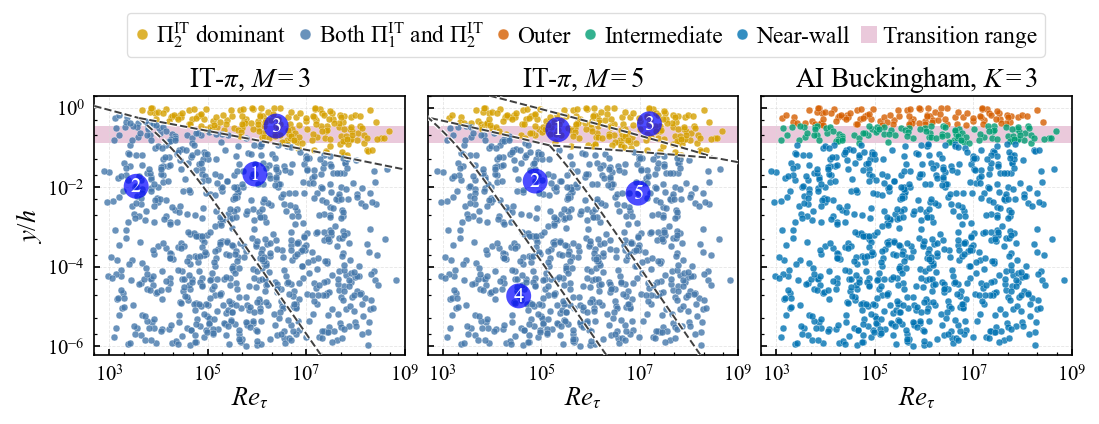

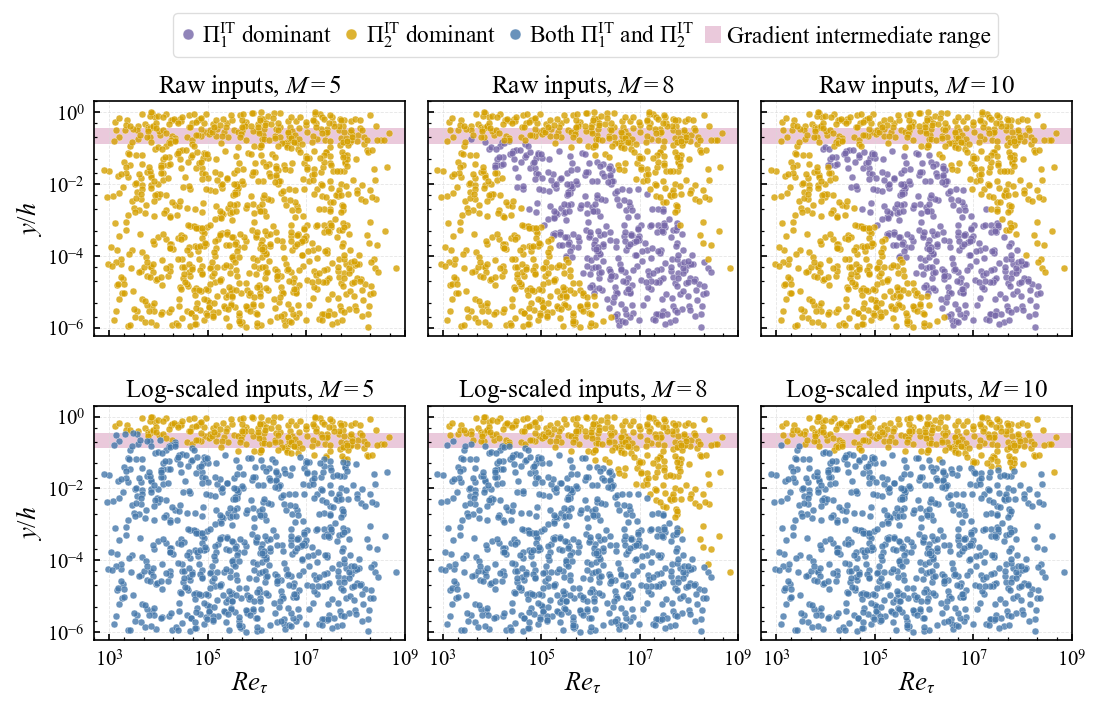

Saved both figures and the full regional-count/seed diagnostics in q:\Work2_agent\2602_Dimensional_agent\Packages_\Sec6.3_ITpi\results


In [114]:
if len(MAIN_M)!=2:
    raise ValueError('MAIN_M 应指定主图前两列的两个区域数。')
render_main()
render_diagnostic()
metadata={
    'main_M':list(MAIN_M),'main_seed':MAIN_SEED,'main_condition':MAIN_CONDITION,
    'regional_counts':sorted(set(REGION_COUNTS)|set(MAIN_M)|set(DIAGNOSTIC_M)),
    'seeds':sorted(set(SEEDS)|{MAIN_SEED}),
    'local_MI':'Unchanged author estimator, k=5, threshold=0.9, X1-first',
    'conditioning':'log_standardized means log(inputs/response), then separate global standardization',
    'geometry':'StandardScaler(log1p(input_PI))',
    'notation':'Pi_i^IT denotes the ith input dimensionless group discovered by IT-pi',
    'transition_range':{'eta_min':INTERMEDIATE_RANGE[0],'eta_max':INTERMEDIATE_RANGE[1],
        'source':'Wall-normal range of the 114 recorded gradient intermediate samples'},
    'plot':PLOT,'MI_colors':MI_COLORS,'gradient_colors':GRADIENT_COLORS,
    'source_hashes':{str(p.relative_to(HERE)):sha(p) for p in [
        HERE/'data/dataset_cess_channel.csv',HERE/'data/recorded_gradient_membership.csv',
        HERE/'vendor/IT_PI.py',fit_path]},
}
(OUT/'figure_settings.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Saved both figures and the full regional-count/seed diagnostics in',OUT)
